# Comprendre, nettoyer et explorer les données

**Support guidé pour la responsabilité données / statistiques / EDA.**
Lis l'explication, exécute la cellule avec **Maj + Entrée**, puis lis son résultat.
Le notebook utilise le vrai CSV fourni dans le projet. Les valeurs affichées ont été calculées.

L'ordre est : comprendre les colonnes, auditer, nettoyer, isoler l'entraînement,
explorer, réaliser deux analyses statistiques, puis transmettre le travail.
Le second notebook traite Zero-R et Naïve Bayes. La vue interactive se trouve dans `src/eda_view.py`.

**Problème étudié :** classer une cellule géographique à une date donnée selon la présence
d'une détection d'incendie (`label=1`) ou son absence dans les données (`label=0`).
Zéro ne prouve pas qu'aucun feu réel n'a eu lieu. Les négatifs sont sélectionnés : la proportion
de positifs du fichier n'est pas une estimation du risque réel en Algérie.

Les conditions météo du jour sont utilisées pour une classification rétrospective.
Pour annoncer un risque avant la journée, il faudrait des prévisions ou des variables décalées.

## 1. Préparer les outils
`pandas` manipule le tableau, `numpy` effectue les calculs et `matplotlib` / `seaborn`
dessinent les graphiques. `Path` permet de retrouver les fichiers sans chemin propre à un ordinateur.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Trouver la racine, que le notebook soit ouvert depuis la racine ou notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/cleaning_guide.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Placer notebooks/ et src/ dans le même dossier de projet.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.cleaning_guide import clean_data
for folder in ['data/processed', 'results', 'figures', 'models']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 130)
print('Dossier du projet trouvé.')

Dossier du projet trouvé.


## 2. Charger le fichier brut
Commence toujours par `dataset.csv`. `processed1.csv` est déjà une version modifiée et contient
un ancien index nommé `Unnamed: 0`. Le code accepte la structure actuelle `Dataset/` ou
la structure du sujet `data/raw/`.

`shape` donne `(nombre de lignes, nombre de colonnes)`. `head()` montre un aperçu.
Une ligne correspond à **une zone et un jour**, pas à un incendie et pas à une zone unique.

In [2]:
candidates = [ROOT / 'data/raw/dataset.csv', ROOT / 'Dataset/dataset.csv']
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Copier votre Dataset/dataset.csv dans data/raw/dataset.csv ou conserver Dataset/.')
raw = pd.read_csv(DATA_PATH)
print('Dimensions :', raw.shape)
print(raw[['cell_id', 'date', 'temp_max', 'rh_mean', 'label']].head().to_string(index=False))
print('Nombre de zones :', raw['cell_id'].nunique())
print('Période :', raw['date'].min(), 'à', raw['date'].max())

Dimensions : (121869, 37)
cell_id       date  temp_max  rh_mean  label
 340_60 2013-06-27      34.4       37      0
 340_60 2013-07-04      38.5       32      0
 340_60 2013-07-15      38.5       30      0
 340_60 2013-09-24      30.9       53      0
 340_60 2014-08-21      40.1       34      1
Nombre de zones : 1423
Période : 2012-06-01 à 2025-10-31


**Résultat attendu sur la version fournie :** 121 869 lignes, 37 colonnes et 1 423 zones.
Cela satisfait le minimum de 10 000 observations et 10 attributs.
Les 37 colonnes comprennent la cible et des métadonnées : ce ne sont pas 37 variables d'entrée.
Le dictionnaire complet des colonnes est dans `docs/dictionnaire_colonnes.md`.

## 3. Auditer les types, les manquants et les doublons
`isna()` repère les valeurs absentes. Une absence n'est pas automatiquement un zéro.
Un doublon exact répète toutes les colonnes ; un doublon de clé répète la même zone au même jour.
La répétition de `cell_id` à des dates différentes est normale.

L'audit global sert à vérifier la structure et la qualité. Les analyses qui orientent les modèles
seront ensuite limitées à `train`.

In [3]:
audit = pd.DataFrame({
    'type': raw.dtypes.astype(str),
    'manquants': raw.isna().sum(),
    'pourcentage_manquant': raw.isna().mean().mul(100).round(4),
    'valeurs_distinctes': raw.nunique()
})
print(audit.to_string())
print('Doublons exacts :', int(raw.duplicated().sum()))
print('Doublons zone/jour :', int(raw.duplicated(['cell_id', 'date']).sum()))
audit.to_csv(ROOT / 'results/audit_colonnes.csv', index_label='colonne')

                         type  manquants  pourcentage_manquant  valeurs_distinctes
cell_id                object          0                0.0000                1423
lat                   float64          0                0.0000                  33
lon                   float64          0                0.0000                 116
date                   object          0                0.0000                2142
year                    int64          0                0.0000                  14
doy                     int64          0                0.0000                 154
label                   int64          0                0.0000                   2
sample_kind            object          0                0.0000                   2
n_detections            int64          0                0.0000                 106
max_frp               float64      91518               75.0954                5690
temp_max              float64          0                0.0000                 398
temp

## 4. Vérifier quelques règles de cohérence
Une température moyenne doit se trouver entre le minimum et le maximum du même jour.
L'humidité relative est comprise entre 0 et 100. La pluie et la vitesse du vent sont positives ou nulles.
Les NDVI doivent être dans [-1, 1]. On compte les anomalies avant de décider d'une correction.

Une température négative, une anomalie NDVI négative ou un FWI élevé n'est pas à supprimer
automatiquement. Les conventions de calcul du FWI de ce jeu doivent être documentées.

In [13]:
dates = pd.to_datetime(raw['date'], errors='coerce')
checks = {
    'dates_invalides': int(dates.isna().sum()),
    'cible_invalide': int((~raw['label'].isin([0, 1])).sum()),
    'ordre_temperature_incoherent': int((raw.temp_min.gt(raw.temp_mean) | raw.temp_mean.gt(raw.temp_max)).sum()),
    'ordre_humidite_incoherent': int(raw.rh_min.gt(raw.rh_mean).sum()),
    'ordre_vent_incoherent': int(raw.wind_mean.gt(raw.wind_max).sum()),
    'year_incoherent': int(raw.year.ne(dates.dt.year).sum()),
    'doy_incoherent': int(raw.doy.ne(dates.dt.dayofyear).sum()),
}
for col in ['rh_min', 'rh_mean']:
    checks[col + '_hors_0_100'] = int((raw[col].notna() & ~raw[col].between(0, 100)).sum())
for col in ['wind_max', 'wind_mean', 'precip_sum', 'precip_7d', 'precip_30d']:
    checks[col + '_negatif'] = int(raw[col].lt(0).sum())
for col in ['ndvi', 'ndvi_normal']:
    checks[col + '_hors_moins1_1'] = int((raw[col].notna() & ~raw[col].between(-1, 1)).sum())
print(pd.Series(checks).to_string())
print('Valeurs spéciales 9999 dans days_since_last_fire :', int(raw.days_since_last_fire.eq(9999).sum()))
print('Valeurs numériques infinies :', int(np.isinf(raw.select_dtypes('number').to_numpy()).sum()))
pd.Series(checks).to_csv(ROOT / 'results/controles_coherence.csv', header=['nombre'])

dates_invalides                 0
cible_invalide                  0
ordre_temperature_incoherent    0
ordre_humidite_incoherent       0
ordre_vent_incoherent           0
year_incoherent                 0
doy_incoherent                  0
rh_min_hors_0_100               0
rh_mean_hors_0_100              0
wind_max_negatif                0
wind_mean_negatif               0
precip_sum_negatif              0
precip_7d_negatif               0
precip_30d_negatif              0
ndvi_hors_moins1_1              0
ndvi_normal_hors_moins1_1       0
Valeurs spéciales 9999 dans days_since_last_fire : 5965
Valeurs numériques infinies : 0


Le notebook existant décrit `9999` comme une absence d'antécédent connu. Ce codage doit être confirmé
dans la documentation d'origine. On ne le présente pas comme une durée réellement mesurée de 9 999 jours.
Aucun contrôle ci-dessus ne justifie à lui seul de déclarer le dataset entièrement exempt d'erreurs.

## 5. Prouver les fuites de la cible
Une fuite survient quand une variable donne la réponse que le modèle est censé apprendre à prédire.
`sample_kind` décrit comment l'exemple a été étiqueté ; `n_detections` et `max_frp` décrivent
les détections du jour. Elles ne sont pas des entrées acceptables pour anticiper ces mêmes détections.

`crosstab` compte les associations entre deux variables. On fabrique des indicateurs temporaires
sans écraser les colonnes originales, contrairement aux cellules 23 et 24 de l'ancien notebook.

In [14]:
print('sample_kind :')
print(pd.crosstab(raw['label'], raw['sample_kind']))
print('n_detections > 0 :')
print(pd.crosstab(raw['label'], raw['n_detections'].gt(0)))
print('max_frp manquant :')
print(pd.crosstab(raw['label'], raw['max_frp'].isna()))

sample_kind :
sample_kind  matched_negative  positive
label                                  
0                       91518         0
1                           0     30351
n_detections > 0 :
n_detections  False  True 
label                     
0             91518      0
1                 0  30351
max_frp manquant :
max_frp  False  True 
label                
0            0  91518
1        30351      0


Ici, les trois relations sont parfaites : `positive`, un nombre de détections supérieur à zéro,
et un `max_frp` renseigné identifient tous la classe 1.
Les 91 518 valeurs manquantes de `max_frp` correspondent exactement aux négatifs.
**Ne fais donc pas `raw.dropna()` : tu supprimerais toute la classe 0.**

## 6. Produire un nettoyage reproductible
Le code complet est dans `src/cleaning_guide.py`. Il travaille sur une copie, convertit la date,
vérifie la cible et les clés, retire les doublons exacts s'il y en a et exclut les trois fuites.
Le fichier brut reste intact. Les médianes, la standardisation et l'encodage relèvent du pipeline commun.

`index=False` évite d'exporter l'index pandas comme une nouvelle colonne `Unnamed: 0`.

In [15]:
df, cleaning_report = clean_data(raw)
print(json.dumps(cleaning_report, ensure_ascii=False, indent=2))
df.to_csv(ROOT / 'data/processed/dataset_clean.csv', index=False, date_format='%Y-%m-%d')
(ROOT / 'results/nettoyage.json').write_text(json.dumps(cleaning_report, ensure_ascii=False, indent=2), encoding='utf-8')
print('Nettoyage enregistré. Dimensions :', df.shape)

{
  "lignes_avant": 121869,
  "colonnes_avant": 37,
  "doublons_exacts_supprimes": 0,
  "colonnes_fuite_exclues": [
    "sample_kind",
    "n_detections",
    "max_frp"
  ],
  "lignes_apres": 121869,
  "colonnes_apres": 34
}
Nettoyage enregistré. Dimensions : (121869, 34)


## 7. Respecter les partitions temporelles
Le dataset contient déjà `split`. Train = 2012-2023, validation = 2024, test = 2025.
Le tableau suivant vérifie les périodes et les volumes, sans évaluer un modèle sur le test.
À partir d'ici, les figures et les tests statistiques utilisent seulement `train`.

Une séparation aléatoire mélangerait passé et futur. Le protocole final appartient à l'équipe,
avec le responsable du prétraitement. Conserver ces années est la proposition de ce guide.

In [7]:
partitions = df.groupby('split').agg(lignes=('date', 'size'), debut=('date', 'min'), fin=('date', 'max'))
print(partitions.to_string())
train = df.loc[df['split'].eq('train')].copy()
print('Lignes utilisables pour l’exploration :', len(train))
print('La colonne split ne sera jamais une variable du modèle.')

       lignes      debut        fin
split                              
test     8467 2025-06-01 2025-10-31
train  104979 2012-06-01 2023-10-31
val      8423 2024-06-01 2024-10-31
Lignes utilisables pour l’exploration : 104979
La colonne split ne sera jamais une variable du modèle.


## 8. Décrire la cible et les données d'entraînement
La fréquence compte les exemples par classe. Le pourcentage permet de voir le déséquilibre.
`describe()` affiche effectif, moyenne, dispersion, minimum, quartiles et maximum.
Le troisième quartile n'est pas une limite de validité physique.

Ces négatifs sont sélectionnés : écris « proportion dans l'échantillon », pas « risque d'incendie du pays ».

       effectif  pourcentage
label                       
0         76393        72.77
1         28586        27.23
         temp_max     rh_mean  precip_sum         fwi        ndvi
count  104979.000  104979.000  104979.000  104979.000  104924.000
mean       30.189      56.426       0.659      45.270       0.384
std         5.691      17.489       2.873      24.394       0.156
min         4.500       8.000       0.000       0.000       0.058
25%        26.300      43.000       0.000      28.071       0.257
50%        30.200      58.000       0.000      45.024       0.369
75%        34.200      70.000       0.100      61.357       0.495
max        48.400     100.000     119.500     225.373       0.850
Manquants sur train :
ndvi_normal        61
ndvi_anomaly       61
ndvi_stale_days    55
ndvi_change_32d    55
ndvi               55


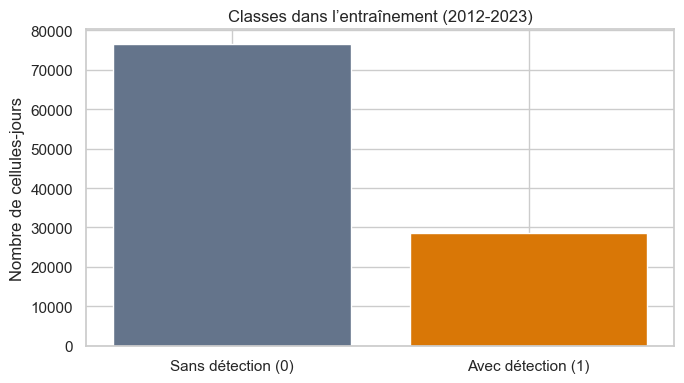

In [8]:
counts = train['label'].value_counts().sort_index()
balance = pd.DataFrame({'effectif': counts, 'pourcentage': counts / len(train) * 100})
print(balance.round(2).to_string())
print(train[['temp_max', 'rh_mean', 'precip_sum', 'fwi', 'ndvi']].describe().round(3).to_string())
missing_train = train.isna().sum().sort_values(ascending=False)
print('Manquants sur train :')
print(missing_train[missing_train > 0].to_string())
train.describe().T.to_csv(ROOT / 'results/statistiques_train.csv', index_label='variable')
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(['Sans détection (0)', 'Avec détection (1)'], counts.values, color=['#64748b', '#d97706'])
ax.set(ylabel='Nombre de cellules-jours', title='Classes dans l’entraînement (2012-2023)')
fig.tight_layout(); fig.savefig(ROOT / 'figures/classes_train.png', dpi=150); plt.show()

## 9. Dessiner et interpréter les distributions
Un histogramme montre où les valeurs se concentrent. La KDE est une courbe de densité lissée,
pas une probabilité d'incendie. `common_norm=False` compare les formes malgré des effectifs différents.
Les graphiques utilisent un échantillon reproductible de 5 000 lignes pour rester rapides.
Les statistiques et analyses utilisent toutes les lignes d'entraînement.

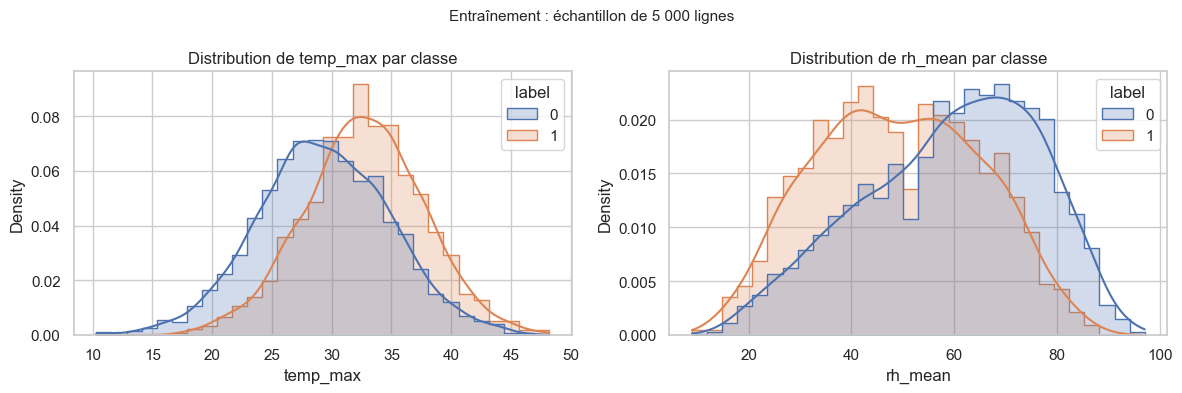

In [16]:
sample = train.sample(n=min(5000, len(train)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for col, ax in zip(['temp_max', 'rh_mean'], axes):
    sns.histplot(data=sample, x=col, hue='label', stat='density', common_norm=False,
                 element='step', bins=30, kde=True, ax=ax)
    ax.set_title(f'Distribution de {col} par classe')
fig.suptitle('Entraînement : échantillon de 5 000 lignes', fontsize=11)
fig.tight_layout(); fig.savefig(ROOT / 'figures/distributions_train.png', dpi=150); plt.show()

## 10. Examiner les corrélations
Une corrélation décrit une association. Elle ne prouve pas une cause.
Plusieurs températures ou composantes FWI peuvent se recouper, ce qui limite l'hypothèse
d'indépendance conditionnelle de Naïve Bayes.
La heatmap sert à commenter ces liens ; elle ne justifie pas une suppression automatique.

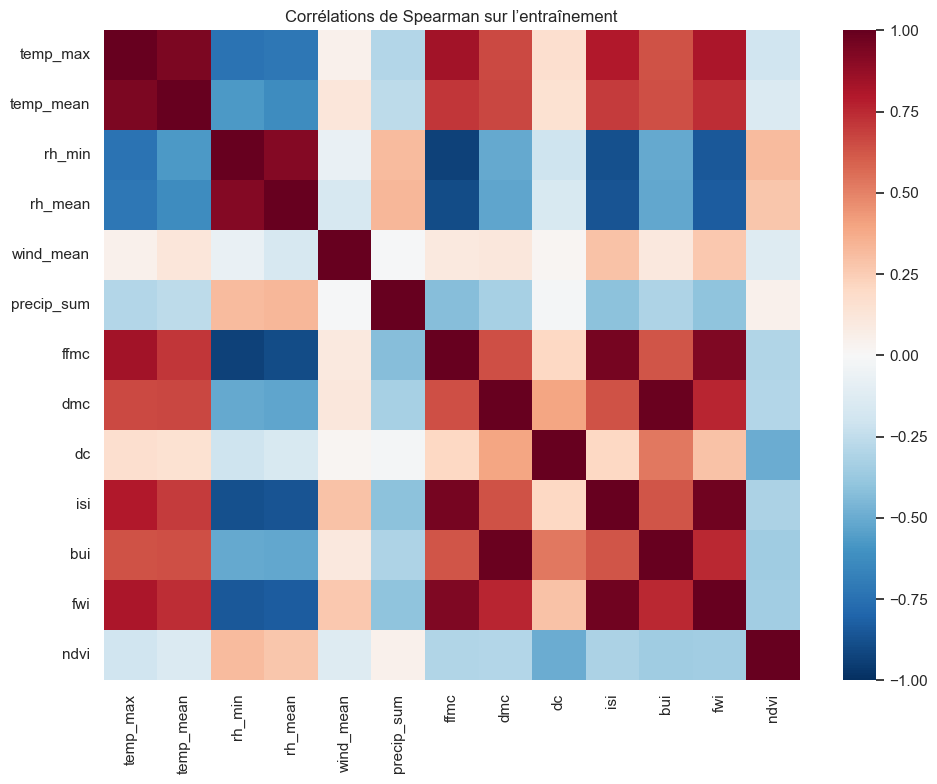

In [10]:
corr_cols = ['temp_max', 'temp_mean', 'rh_min', 'rh_mean', 'wind_mean', 'precip_sum', 'ffmc', 'dmc', 'dc', 'isi', 'bui', 'fwi', 'ndvi']
corr = train[corr_cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, vmin=-1, vmax=1, center=0, cmap='RdBu_r', ax=ax)
ax.set_title('Corrélations de Spearman sur l’entraînement')
fig.tight_layout(); fig.savefig(ROOT / 'figures/correlations_train.png', dpi=150); plt.show()
corr.to_csv(ROOT / 'results/correlations_train.csv', index_label='variable')

## 11. Réaliser deux analyses statistiques adaptées à la structure

**Question 1 :** dans les saisons d'entraînement, la température maximale diffère-t-elle de façon
cohérente entre jours avec et sans détection, à zone et saison comparables ?
**Question 2 :** la même question pour l'humidité moyenne.

On ne considère pas les 104 979 lignes comme 104 979 observations indépendantes.
Pour chaque variable :

1. Calculer la moyenne des jours de chaque classe dans chaque couple `(cell_id, year)`.
2. Ne garder que les couples comportant les deux classes.
3. Calculer l'écart `moyenne(label=1) - moyenne(label=0)` dans chaque couple.
4. Moyenner ces écarts entre zones d'une même année. Chaque zone a le même poids.
5. Appliquer un **test des signes** aux 12 écarts annuels, à l'aide d'un test binomial exact.

**H0 :** la probabilité d'un écart annuel strictement positif, parmi les écarts non nuls, vaut 0,5.
**H1 :** elle diffère de 0,5. La statistique est le nombre d'années avec un écart positif,
parmi les années avec écart non nul. Ce n'est pas un test d'égalité de toutes les distributions.

**Conditions et limites :** l'inférence suppose des signes annuels approximativement indépendants.
L'agrégation réduit la fausse multiplication des observations, mais ne garantit pas cette indépendance
entre saisons. Avec seulement 12 saisons et des négatifs appariés, les p-values sont exploratoires et
conditionnelles à cette hypothèse. Les écarts descriptifs restent à rapporter si elle est contestée.
Cette procédure est une proposition à relire avec le responsable du protocole, pas un test imposé par le cours.

On corrige les deux p-values par **Holm** pour tenir compte des deux tests.
La taille d'effet descriptive est la moyenne des écarts annuels, avec leur plage.

In [11]:
from scipy.stats import binomtest
yearly_gaps = {}
paired_counts = {}
records = []
for variable in ['temp_max', 'rh_mean']:
    paired = train.groupby(['year', 'cell_id', 'label'])[variable].mean().unstack('label')
    paired = paired.dropna(subset=[0, 1])
    gaps = paired[1] - paired[0]
    annual = gaps.groupby(level='year').mean()
    yearly_gaps[variable] = annual
    paired_counts[variable] = gaps.groupby(level='year').size()
    nonzero = annual.loc[annual.ne(0)]
    n = len(nonzero)
    k = int(nonzero.gt(0).sum())
    p = binomtest(k, n, p=0.5, alternative='two-sided').pvalue if n else np.nan
    records.append({'variable': variable, 'annees_non_nulles': n, 'annees_ecart_positif': k,
                    'ecart_annuel_moyen': annual.mean(), 'ecart_annuel_min': annual.min(),
                    'ecart_annuel_max': annual.max(), 'p_brute': p})
stats_results = pd.DataFrame(records)
# Correction de Holm : ordre croissant, multiplication, puis maximum cumulatif.
order = np.argsort(stats_results['p_brute'].to_numpy())
p_sorted = stats_results['p_brute'].to_numpy()[order]
adjusted_sorted = np.minimum(1, np.maximum.accumulate(p_sorted * np.arange(len(p_sorted), 0, -1)))
adjusted = np.empty(len(p_sorted))
adjusted[order] = adjusted_sorted
stats_results['p_holm'] = adjusted
print('Écarts annuels (classe 1 moins classe 0) :')
print(pd.DataFrame(yearly_gaps).round(3).to_string())
print('Nombre de zones comparables par année :')
print(pd.DataFrame(paired_counts).to_string())
print('Résultats exploratoires sous l’hypothèse d’indépendance des signes annuels :')
print(stats_results.to_string(index=False))
pd.DataFrame(yearly_gaps).to_csv(ROOT / 'results/ecarts_annuels.csv', index_label='annee')
pd.DataFrame(paired_counts).to_csv(ROOT / 'results/nombres_zones_appariees.csv', index_label='annee')
stats_results.to_csv(ROOT / 'results/analyses_statistiques.csv', index=False)

Écarts annuels (classe 1 moins classe 0) :
      temp_max  rh_mean
year                   
2012     4.052  -10.658
2013     2.842  -10.486
2014     3.307   -8.420
2015     3.843   -9.164
2016     2.391   -7.702
2017     3.893  -13.082
2018     2.556   -6.912
2019     3.206  -10.992
2020     3.845  -11.736
2021     3.605  -12.647
2022     0.929   -8.793
2023     2.454  -10.687
Nombre de zones comparables par année :
      temp_max  rh_mean
year                   
2012       805      805
2013       711      711
2014       770      770
2015       608      608
2016       689      689
2017       693      693
2018       530      530
2019       729      729
2020       708      708
2021       553      553
2022       511      511
2023       405      405
Résultats exploratoires sous l’hypothèse d’indépendance des signes annuels :
variable  annees_non_nulles  annees_ecart_positif  ecart_annuel_moyen  ecart_annuel_min  ecart_annuel_max  p_brute   p_holm
temp_max                 12                 

**Lecture des résultats de la version fournie :** l'écart de `temp_max` est positif dans les 12 saisons,
avec une moyenne d'environ **+3,08 unités du CSV**. L'écart de `rh_mean` est négatif dans les 12 saisons,
avec une moyenne d'environ **-10,11 points d'humidité relative**. Chaque p-value brute vaut
0,00048828125 ; après Holm, 0,0009765625.

Sous l'hypothèse d'indépendance des signes annuels, ces signes systématiques conduisent à rejeter H0
au seuil de 5 %. La conclusion descriptive est que, dans cet échantillon et après la comparaison
par zone/saison, les jours étiquetés positifs sont en moyenne plus chauds et moins humides.
**Cela ne démontre ni causalité ni risque absolu**, et les p-values ne prouvent pas l'indépendance.
Confirmer l'unité de température à la source avant de remplacer « unités du CSV » par « °C ».

## 12. Visualiser les écarts annuels
La ligne zéro signifie absence d'écart moyen. Les barres montrent aussi l'ampleur des écarts,
information que la p-value seule ne donne pas.

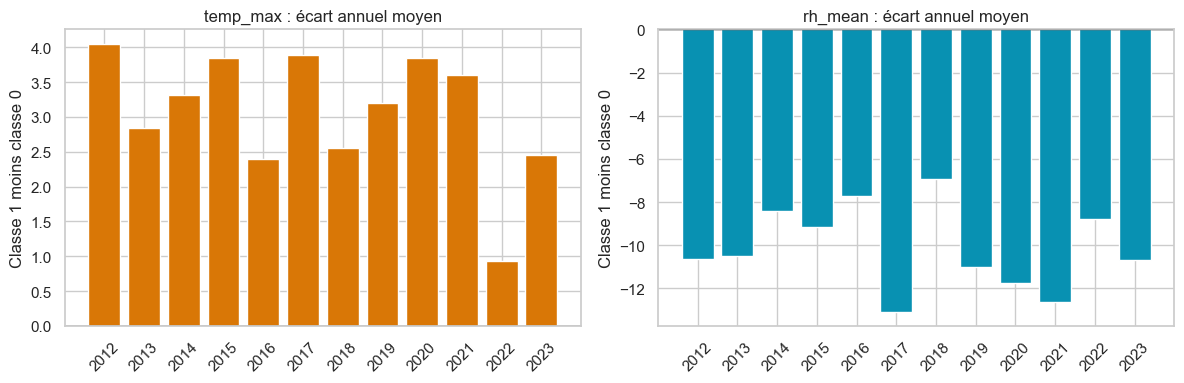

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for variable, ax in zip(['temp_max', 'rh_mean'], axes):
    values = yearly_gaps[variable]
    ax.bar(values.index.astype(str), values.values, color='#d97706' if variable == 'temp_max' else '#0891b2')
    ax.axhline(0, color='black', linewidth=1)
    ax.set_title(variable + ' : écart annuel moyen')
    ax.set_ylabel('Classe 1 moins classe 0')
    ax.tick_params(axis='x', rotation=45)
fig.tight_layout(); fig.savefig(ROOT / 'figures/ecarts_annuels.png', dpi=150); plt.show()

## 13. Transmettre ton travail

Au responsable du prétraitement : le CSV nettoyé **non imputé**, la fonction de nettoyage,
le dictionnaire, les trois exclusions pour fuite, les contrôles et les observations sur les manquants.
Confirmer ensemble les entrées du modèle, le sens de `9999`, les unités et l'horizon de prédiction.

Au responsable de l'application : `src/eda_view.py`, ses dépendances et les figures.
La fonction `render_eda(df)` affiche les six éléments demandés et conserve le filtre `train`.

Pour le rapport : expliquer le sens d'une ligne, la cible, les manquants, les décisions de nettoyage,
puis chaque figure et chaque analyse. Un graphique sans commentaire n'est pas une analyse.
Employer ton **code étudiant** sur les supports publics, conformément au sujet.

Poursuis ensuite avec `03_zeror_naive_bayes.ipynb`. Les choix de ce second notebook
sont une base de travail à harmoniser avec les quatre autres modèles de l'équipe.